# University RAG Assistant — Annotated Notebook

## What this notebook builds

This project is a **retrieval-augmented generation (RAG) assistant** for university questions. It searches local syllabi, student guidelines, and policy documents, then asks a language model to draft an answer using the retrieved passages as evidence.

The notebook has two different classification-like stages that should not be confused:

1. **Topic routing (DeBERTa-v3):** a three-class classifier that predicts `UNIVERSITY_POLICY`, `COURSE_SYLLABUS`, or `GENERAL_INQUIRY`. Its purpose is to guide retrieval, not to decide whether an answer is safe to send.
2. **Binary answerability decision (confidence gate):** a rule that converts a composite score into one of two actions: `AUTO-ANSWERED` or `ESCALATED`. This is a threshold-based decision over heuristic signals; the notebook does **not** train a separate binary classifier.

## RAG in a few steps

`Documents → text extraction → chunks → embeddings → vector store`

`Student question → topic routing → query embedding → top-k retrieval → context-grounded answer → confidence gate`

The retriever finds passages that are close to the question in embedding space. The generator then receives those passages as context. A confidence gate reduces the chance of returning an unsupported draft by withholding answers whose score is below a chosen threshold.

## Five phases covered

- **Setup & Data Ingestion:** dependencies, environment configuration, document extraction, and public QA/intent data.
- **Chunking:** split long documents into overlapping passages that can be retrieved independently.
- **Evaluation Split & Vector Store:** prepare calibration/test questions, embed local passages, store them in ChromaDB, and configure routing/retrieval/generation.
- **Confidence Gating & Evaluation Results:** calculate a composite score, inspect threshold trade-offs, and evaluate on held-out data.
- **Live Gradio Demo & Safeguards:** expose the pipeline and show how low-confidence, empty-retrieval, timeout, and runtime-error cases are handled.

> **How to read this notebook:** Markdown cells explain the purpose and theory; comments inside code explain important transformations and decisions. Existing code and configuration are preserved. Environment-specific paths, model files, API keys, and local services still need to be configured before execution.

## Phase 1 — Setup & Data Ingestion

### 1A. Imports, environment, and runtime switches

The first code cell imports the libraries used for document processing, tabular data, model inference, embeddings, vector storage, and the demo. It loads secrets from `RAG_Project_Setup.env` and defines flags/paths for the two-stage workflow.

**Key idea:** configuration is centralized so the notebook can switch between public-data transfer and local deployment, and between local inference and an optional hosted fallback. API keys should remain in the environment file and should not be committed to source control.

In [ ]:
# CELL 1: Step 1 - Imports & Environment Setup
import os
import re
import json
import time
from pathlib import Path
from typing import Optional, Tuple, List, Any, Dict

import requests
import onnxruntime as ort
from transformers import AutoTokenizer
from pypdf import PdfReader
from docx import Document
from pdf2image import convert_from_path
import pytesseract

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

from sentence_transformers import SentenceTransformer
import chromadb

from google import genai
from google.genai import types
from pydantic import BaseModel

from dotenv import load_dotenv

notebook_dir = Path().resolve()
env_path = notebook_dir / "RAG_Project_Setup.env"
load_dotenv(dotenv_path=env_path)
hf_token = os.getenv("HF_TOKEN")

if "GEMINI_API_KEY" in os.environ and os.environ["GEMINI_API_KEY"].strip():
    print("GEMINI_API_KEY loaded successfully!")
else:
    print(f"GEMINI_API_KEY not set. Checked: {env_path} (exists={env_path.exists()})")

# Two-Phase Workflow Configuration Flags
PHASE_1_PUBLIC_TRANSFER = True
PHASE_2_LOCAL_DEPLOYMENT = True

# Local CPU ONNX Runtime DeBERTa-v3 Router Configuration
USE_LOCAL_DEBERTA_ONNX = True
DEBERTA_ONNX_MODEL_PATH = os.environ.get(
    "DEBERTA_ONNX_MODEL_PATH",
    "./models/deberta-v3-onnx/model.onnx",
)
DEBERTA_TOKENIZER_DIR = os.environ.get(
    "DEBERTA_TOKENIZER_DIR",
    "./models/deberta-v3-onnx",
)
DEBERTA_LABELS = ["UNIVERSITY_POLICY", "COURSE_SYLLABUS", "GENERAL_INQUIRY"]

# Local Ollama Phi-4-mini Configuration
USE_LOCAL_PHI4_MINI = True
OLLAMA_URL = os.environ.get("OLLAMA_URL", "http://localhost:11434/api/chat")
PHI4_MODEL = os.environ.get("PHI4_MODEL", "phi4-mini")
ALLOW_GEMINI_FALLBACK = True

c:\Users\seanm\VS_repos\SemProject_MLEngine\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GEMINI_API_KEY loaded successfully!


### 1B. Extract and normalize the local knowledge base

A RAG system needs searchable source material before it can answer questions. The next cell scans `course_documents`, `student_guidelines`, and `university_policies`.

- **PDF:** try embedded text extraction first; when no text is found, render pages and use OCR.
- **DOCX:** extract both paragraphs and table cells.
- **Cleaning:** normalize whitespace while retaining meaningful line separation.
- **Metadata:** detect a course code and document type, then keep them with the cleaned text.

The result, `documents_dict`, is a dictionary of source documents. It is not yet a vector store; chunking and indexing happen later.

In [ ]:
# CELL 2: Step 2 - Document Extraction (Syllabi, Guidelines & Policy Docs)
def extract_text_from_pdf(file_path: str) -> str:
    """Extracts text from a standard PDF. Falls back to OCR if scanned."""
    text = ""
    try:
        reader = PdfReader(file_path)
        for page in reader.pages:
            page_text = page.extract_text()
            if page_text:
                text += page_text + "\n"

        if not text.strip():
            print(f"  -> No digital text in {os.path.basename(file_path)}. Running OCR...")
            text = extract_text_via_ocr(file_path)
    except Exception as e:
        print(f"Error reading PDF {file_path}: {e}")
    return text


def extract_text_via_ocr(file_path: str) -> str:
    """Converts PDF pages into images and extracts text using Tesseract OCR."""
    ocr_text = ""
    try:
        pages = convert_from_path(file_path, dpi=200)
        for i, page in enumerate(pages):
            page_text = pytesseract.image_to_string(page)
            if page_text:
                ocr_text += f"\n--- OCR Page {i+1} ---\n{page_text}\n"
    except Exception as e:
        print(f"  -> OCR failed for {file_path}: {e}")
    return ocr_text


def extract_text_from_docx(file_path: str) -> str:
    """Extracts text from an MS Word (.docx) file, covering body text and tables."""
    text = ""
    try:
        doc = Document(file_path)
        for paragraph in doc.paragraphs:
            if paragraph.text.strip():
                text += paragraph.text + "\n"

        if doc.tables:
            text += "\n--- Table Data Extracted ---\n"
            for table in doc.tables:
                for row in table.rows:
                    row_cells = [cell.text.strip() for cell in row.cells if cell.text.strip()]
                    if row_cells:
                        cleaned_row = []
                        for cell in row_cells:
                            if not cleaned_row or cleaned_row[-1] != cell:
                                cleaned_row.append(cell)
                        text += " | ".join(cleaned_row) + "\n"
    except Exception as e:
        print(f"Error reading DOCX {file_path}: {e}")
    return text


def clean_text(text: str) -> str:
    """Normalizes whitespace and removes blank lines."""
    lines = [re.sub(r"\s+", " ", line).strip() for line in text.splitlines() if line.strip()]
    return "\n".join(lines)


def _normalize_course_code(code: str) -> str:
    """Normalizes spacing and casing for course codes (e.g., 'ics2101' -> 'ICS 2101')."""
    cleaned = re.sub(r"\s+", " ", str(code or "").strip().upper())
    m = re.match(r"^([A-Z]{2,4})\s?(\d{3,4})$", cleaned)
    return f"{m.group(1)} {m.group(2)}" if m else cleaned


def _normalize_course_name(name: str) -> str:
    """Normalizes course/unit titles for case-insensitive phrase matching."""
    low = re.sub(r"\([^)]*\)", " ", str(name or "").lower())
    low = re.sub(r"\b(course\s*outline|syllabus|blended|ft|part\s*time|full\s*time|unit|course|module)\b", " ", low)
    low = re.sub(r"[^a-z0-9\s]+", " ", low)
    low = re.sub(r"\s+", " ", low).strip()
    return low


MANUAL_COURSE_CODE_OVERRIDES = {
    "ICS 2102 Web Application Development Course Outline.pdf": "ICS 2102",
    # "Student_Handbook_2026.pdf": "UNIVERSITY_POLICY",
}

# Explicit course name -> course code aliases (supplemented automatically from ingested files)
MANUAL_COURSE_NAME_TO_CODE: Dict[str, str] = {
    "business ethics": "HHE 3208",
    "east african societies": "HHE 3108",
    "world civilizations ii": "HHE 3210",
    "probability and statistics i": "ICS 2206",
    "advanced networking": "ICS 2203",
    "advanced database systems": "ICS 3101",
    "software engineering": "ICS 2201",
    "digital logic": "ICS 2211",
    "data structures and algorithms": "ICS 1201",
    "object oriented programming ii": "ICS 2101",
    "microprocessors": "ICS 3111",
    "introduction to programming": "ICS 1102",
    "differential calculus": "ICS 1103",
    "calculus 1": "ICS 1103",
    "principles of management": "ICS 1206",
    "web application development": "ICS 2102",
    "mobile application development": "ICS 3102",
    "assembly language programming": "ICS 3202",
    "computer graphics": "ICS 3204",
    "integral calculus": "BBT 2104",
    "philosophical anthropology": "HED 1101",
    "linear algebra": "ICS 1205",
}

COURSE_NAME_TO_CODE: Dict[str, str] = {}


def _extract_candidate_course_names(text: str, filename: str, course_code: str) -> List[str]:
    """Extracts normalized unit/course names from filename and leading syllabus lines."""
    candidates: List[str] = []

    stem = Path(filename).stem
    stem_no_code = re.sub(r"\b[A-Za-z]{2,4}\s?\d{3,4}\b", " ", stem)
    stem_no_code = re.sub(r"\b(0\.?\s*course\s*outline|course\s*outline|outline|ics\s*csn|\d{4}|july-oct|april)\b", " ", stem_no_code, flags=re.IGNORECASE)
    norm_stem = _normalize_course_name(stem_no_code)
    if norm_stem and len(norm_stem) >= 4:
        candidates.append(norm_stem)

    # Also inspect first ~12 non-empty lines of extracted text for course title patterns
    for line in text.splitlines()[:12]:
        low = line.lower()
        if any(k in low for k in ("title", "course", "unit", "calculus", "algebra", "ethics", "networking", "database", "programming", "logic", "graphics", "anthropology", "civilizations", "societies", "management", "statistics", "engineering", "microprocessors")):
            cleaned_line = re.sub(r"^.*?(?:course\s*(?:title|name)?|unit\s*(?:title|name)?)\s*[:\-]\s*", "", low)
            cleaned_line = re.sub(r"\b[a-z]{2,4}\s?\d{3,4}\b", " ", cleaned_line)
            norm_line = _normalize_course_name(cleaned_line)
            if norm_line and 4 <= len(norm_line) <= 80 and norm_line not in candidates:
                candidates.append(norm_line)

    # Keep only candidates when a real course code is known
    if course_code and course_code not in {"UNKNOWN", "UNIVERSITY_POLICY"}:
        return candidates
    return []


def rebuild_course_name_index(extracted_data: Dict[str, Dict[str, Any]]) -> Dict[str, str]:
    """Rebuilds COURSE_NAME_TO_CODE mapping normalized unit titles to normalized course_code."""
    mapping: Dict[str, str] = {}

    for raw_name, raw_code in MANUAL_COURSE_NAME_TO_CODE.items():
        norm_name = _normalize_course_name(raw_name)
        norm_code = _normalize_course_code(raw_code)
        if norm_name and norm_code:
            mapping[norm_name] = norm_code

    for doc_key, info in (extracted_data or {}).items():
        code = _normalize_course_code((info or {}).get("course_code", ""))
        if not code or code in {"UNKNOWN", "UNIVERSITY_POLICY"}:
            continue
        filename = Path(doc_key).name
        text = (info or {}).get("text", "")
        for cand_name in _extract_candidate_course_names(text, filename, code):
            mapping.setdefault(cand_name, code)

    return mapping


def resolve_course_code_from_query(query: str) -> Optional[str]:
    """Resolves an explicit course code or a known course/unit name inside a query string."""
    if not query or not isinstance(query, str):
        return None

    # 1. Direct course code match (e.g., 'ICS 3203', 'bbt2104')
    code_match = re.search(r"\b([A-Za-z]{2,4})\s?(\d{3,4})\b", query)
    if code_match:
        return f"{code_match.group(1).upper()} {code_match.group(2)}"

    # 2. Course name / unit title match (longest phrase first to avoid partial collisions)
    norm_query = _normalize_course_name(query)
    if not norm_query:
        return None

    active_map = COURSE_NAME_TO_CODE if COURSE_NAME_TO_CODE else {
        _normalize_course_name(k): _normalize_course_code(v)
        for k, v in MANUAL_COURSE_NAME_TO_CODE.items()
    }

    for course_name in sorted(active_map.keys(), key=len, reverse=True):
        if len(course_name) >= 4 and re.search(rf"\b{re.escape(course_name)}\b", norm_query):
            return active_map[course_name]

    return None


def detect_course_code_and_type(text: str, filename: str) -> Tuple[str, str]:
    """Tags documents with course_code and doc_type (course_syllabus, policy_guidelines)."""
    lower_name = filename.lower()
    if any(k in lower_name for k in ["policy", "guidelines", "handbook", "regulation"]):
        doc_type = "policy_guidelines"
    else:
        doc_type = "course_syllabus"

    if filename in MANUAL_COURSE_CODE_OVERRIDES:
        return _normalize_course_code(MANUAL_COURSE_CODE_OVERRIDES[filename]), doc_type

    match = re.search(r"\b([A-Za-z]{2,4}\s?\d{3,4})\b", text[:2500])
    if match:
        code = _normalize_course_code(match.group(1))
    else:
        # Fallback to matching course title in filename or text against known course names
        matched_from_title = resolve_course_code_from_query(f"{Path(filename).stem} {text[:1000]}")
        if matched_from_title:
            code = matched_from_title
        elif doc_type == "policy_guidelines":
            code = "UNIVERSITY_POLICY"
        else:
            code = "UNKNOWN"

    return code, doc_type


def process_document_folders(folder_paths: List[str]) -> dict:
    """Processes expanded local folders for syllabi, student guidelines, and policies."""
    global COURSE_NAME_TO_CODE
    extracted_data = {}
    for folder_path in folder_paths:
        if not os.path.exists(folder_path):
            print(f"Folder not found (skipping): {folder_path}")
            continue
        for file_name in sorted(os.listdir(folder_path)):
            file_path = os.path.join(folder_path, file_name)
            if os.path.isdir(file_path) or file_name.startswith("~$"):
                continue

            print(f"Processing: {file_path}...")
            raw_text = ""
            if file_name.lower().endswith(".pdf"):
                raw_text = extract_text_from_pdf(file_path)
            elif file_name.lower().endswith(".docx"):
                raw_text = extract_text_from_docx(file_path)
            elif file_name.lower().endswith(".doc"):
                print(f"  -> Legacy .doc detected ({file_name}). Convert to .docx or PDF first.")
                continue
            else:
                continue

            if raw_text.strip():
                cleaned = clean_text(raw_text)
                course_code, doc_type = detect_course_code_and_type(cleaned, file_name)
                doc_key = f"{Path(folder_path).name}/{file_name}"
                extracted_data[doc_key] = {
                    "text": cleaned,
                    "course_code": course_code,
                    "doc_type": doc_type,
                }
                print(f"  -> OK ({len(cleaned)} chars) | course_code={course_code} | doc_type={doc_type}")
            else:
                print(f"  -> Warning: could not extract text from {file_name}")

    COURSE_NAME_TO_CODE = rebuild_course_name_index(extracted_data)
    print(f"Indexed {len(COURSE_NAME_TO_CODE)} course name -> code mappings.")
    return extracted_data


local_doc_folders = [
    "./course_documents",
    "./student_guidelines",
    "./university_policies",
]
documents_dict = process_document_folders(local_doc_folders)
print(f"\nTotal local documents processed: {len(documents_dict)}")

Processing: ./course_documents\0. Course Outline_Business Ethics_2025.pdf...
  -> OK (6435 chars) | course_code=HHE 3208 | doc_type=course_syllabus
Processing: ./course_documents\COURSE OUTLINE East African Socities.docx...
  -> OK (8479 chars) | course_code=HHE 3108 | doc_type=course_syllabus
Processing: ./course_documents\COURSE OUTLINE World Civilizations II.docx...
  -> OK (9636 chars) | course_code=HHE 3210 | doc_type=course_syllabus
Processing: ./course_documents\COURSE OUTLINE_ ICS 2206_PROBABILITY AND STATISTICS I.pdf...
  -> OK (7526 chars) | course_code=ICS 2206 | doc_type=course_syllabus
Processing: ./course_documents\Course Outline - ICS2203 - Advanced Networking.pdf...
  -> OK (10715 chars) | course_code=ICS 2203 | doc_type=course_syllabus
Processing: ./course_documents\Course Outline Advanced Database Systems.pdf...
  -> OK (5870 chars) | course_code=ICS 3101 | doc_type=course_syllabus
Processing: ./course_documents\Course Outline ICS 2201 Software Engineering.pdf...
  ->

### 1C. Public intent/QA data preparation and diagnostics

The next cells are data-preparation helpers and exploratory checks for public question examples:

- The JSON repair cell is a **one-off maintenance step** for a file at a hard-coded Windows path. It rewrites that file, so back it up and update the path before running it.
- The JSON inspection cell reports the file structure so the parser can match the real schema.
- The first Kaggle parser and the direct Hugging Face load are exploratory/standalone versions. The consolidated loader in the Phase 1 cell below defines reusable functions and orchestrates both sources.

The public examples are normalized to a shared tabular structure so data from different sources can be concatenated consistently.

In [ ]:
#Cell 3
import json
from pathlib import Path

path = Path(r"C:\Users\seanm\VS_repos\SemProject_MLEngine\data\public\intents.json")
raw_text = path.read_text(encoding="utf-8", errors="replace")

# Find the start of the JSON object and decode only the valid JSON prefix
start = raw_text.find("{")
decoder = json.JSONDecoder()
data, end_idx = decoder.raw_decode(raw_text[start:])

# Overwrite with clean JSON (removes trailing binary/pickle garbage)
path.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")

print("Cleaned successfully. Number of intents:", len(data.get("intents", [])))

Cleaned successfully. Number of intents: 39


In [ ]:
# CELL 4: Dataset discovery and format inspection.
# This is a diagnostic cell: locate intents.json, inspect its top-level shape,
# and print one example before writing a parser for the actual structure.

from pathlib import Path
import json

matches = list(Path(".").rglob("intents.json"))
print("Found intents.json files:", [str(p.resolve()) for p in matches])

if matches:
    p = matches[0]
    print("File size (bytes):", p.stat().st_size)
    raw = p.read_text(encoding="utf-8", errors="replace")
    print("First 400 chars:\n", raw[:400])
    parsed = json.loads(raw)
    print("Top-level type:", type(parsed))
    if isinstance(parsed, dict):
        print("Top-level keys:", list(parsed.keys()))
        if "intents" in parsed and parsed["intents"]:
            print("Sample intent keys & entry:", parsed["intents"][0])
    elif isinstance(parsed, list) and parsed:
        print("First item keys & entry:", parsed[0])

Found intents.json files: ['C:\\Users\\seanm\\VS_repos\\SemProject_MLEngine\\data\\public\\intents.json']
File size (bytes): 31519
First 400 chars:
 {
  "intents": [
    {
      "intent": "greeting",
      "text": [
        "Hi",
        "How are you?",
        "Is anyone there?",
        "Hello",
        "Good day",
        "What's up",
        "how are ya",
        "heyy",
        "whatsup",
        "??? ??? ??"
      ],
      "responses": [
        "Hello!",
        "Good to see you again!",
        "Hi there, how can I help?"
      ],
    
Top-level type: <class 'dict'>
Top-level keys: ['intents']
Sample intent keys & entry: {'intent': 'greeting', 'text': ['Hi', 'How are you?', 'Is anyone there?', 'Hello', 'Good day', "What's up", 'how are ya', 'heyy', 'whatsup', '??? ??? ??'], 'responses': ['Hello!', 'Good to see you again!', 'Hi there, how can I help?'], 'extension': {'function': '', 'entities': False, 'responses': []}, 'context': {'in': '', 'out': 'GreetingUserRequest', 'clear':

In [5]:
# CELL 5: Flexible parser for university-chatbot intent JSON.
# It normalizes different possible JSON layouts into one tabular schema.
# The later Phase 1 loader in CELL 7 defines a function with the same name
# and is the loader called by the final public-dataset orchestration.

from pathlib import Path
import json
import pandas as pd


# Accept either one string or a list of strings and return clean text values.
def _extract_text_items(val) -> list[str]:
    if isinstance(val, list):
        return [str(x).strip() for x in val if x is not None and str(x).strip()]
    if isinstance(val, str) and val.strip():
        return [val.strip()]
    return []


# Output columns are deliberately standardized so this source can be combined
# with other question datasets using pd.concat.
def load_kaggle_university_intents(intents_json_path: str = "./data/public/intents.json") -> pd.DataFrame:
    pref = Path(intents_json_path)
    found_path = pref if pref.exists() else next(iter(Path(".").rglob("intents.json")), None)

    if found_path is None:
        print(f"No intents.json found starting from {Path('.').resolve()}")
        return pd.DataFrame(columns=["question_text", "intent_tag", "sample_response", "source"])

    if found_path.stat().st_size == 0:
        print(f"Warning: {found_path} is 0 bytes (empty file).")
        return pd.DataFrame(columns=["question_text", "intent_tag", "sample_response", "source"])

    try:
        with open(found_path, "r", encoding="utf-8") as f:
            data = json.load(f)
    except Exception as e:
        print(f"Failed to parse JSON in {found_path}: {e}")
        return pd.DataFrame(columns=["question_text", "intent_tag", "sample_response", "source"])

    rows = []

    if isinstance(data, dict):
        # Standard {"intents": [...]} layout or a dict mapping tag -> list of patterns
        if "intents" in data and isinstance(data["intents"], list):
            for intent in data["intents"]:
                if not isinstance(intent, dict):
                    continue
                tag = str(intent.get("tag") or intent.get("intent") or intent.get("label") or "general").strip()
                resps = _extract_text_items(intent.get("responses") or intent.get("response") or intent.get("answers"))
                sample_resp = resps[0] if resps else ""
                patterns = _extract_text_items(
                    intent.get("patterns")
                    or intent.get("questions")
                    or intent.get("queries")
                    or intent.get("utterances")
                    or intent.get("text")
                )
                for q_text in patterns:
                    rows.append({
                        "question_text": q_text,
                        "intent_tag": tag,
                        "sample_response": sample_resp,
                        "source": "kaggle_university_chatbot",
                    })
        else:
            for tag, val in data.items():
                for q_text in _extract_text_items(val):
                    rows.append({
                        "question_text": q_text,
                        "intent_tag": str(tag).strip(),
                        "sample_response": "",
                        "source": "kaggle_university_chatbot",
                    })

    elif isinstance(data, list):
        for item in data:
            if isinstance(item, dict):
                tag = str(item.get("tag") or item.get("intent") or item.get("category") or "general").strip()
                resps = _extract_text_items(item.get("responses") or item.get("response") or item.get("answer"))
                sample_resp = resps[0] if resps else ""
                patterns = _extract_text_items(
                    item.get("patterns") or item.get("pattern") or item.get("question") or item.get("questions") or item.get("text")
                )
                for q_text in patterns:
                    rows.append({
                        "question_text": q_text,
                        "intent_tag": tag,
                        "sample_response": sample_resp,
                        "source": "kaggle_university_chatbot",
                    })

    print(f"Parsed {len(rows)} rows from {found_path}")
    return pd.DataFrame(rows, columns=["question_text", "intent_tag", "sample_response", "source"])

In [6]:
# CELL 6: Standalone Hugging Face QA dataset inspection/load.
# This is an exploratory version of the loader. CELL 7 later wraps the same
# source in a reusable function with a local-file fallback.

from datasets import load_dataset
import pandas as pd

# Load a question/answer dataset from the Hugging Face Hub. This requires
# network access and the `datasets` package.
ds = load_dataset("adikuma/qa_dataset")
print("Available splits:", list(ds.keys()))

# 2. Pick the split (usually "train", or the first available split)
split_name = "train" if "train" in ds else list(ds.keys())[0]
hf_raw_df = ds[split_name].to_pandas()

print("Columns:", list(hf_raw_df.columns))
print("Row count:", len(hf_raw_df))
hf_raw_df.head(3)

# Detect likely question/answer column names, then map them to the shared schema.
# The constant intent label keeps these general QA examples distinct from
# the university-intent examples.
q_col = next((c for c in ["question", "query", "prompt", "instruction", "input"] if c in hf_raw_df.columns), hf_raw_df.columns[0])
a_col = next((c for c in ["answer", "response", "output"] if c in hf_raw_df.columns), None)

hf_df = pd.DataFrame({
    "question_text": hf_raw_df[q_col].astype(str).str.strip(),
    "sample_response": hf_raw_df[a_col].astype(str).str.strip() if a_col else "",
    "intent_tag": "general_qa",
    "source": "hf_adikuma_qa_dataset",
})

hf_df = hf_df[hf_df["question_text"] != ""].reset_index(drop=True)
print(f"Prepared {len(hf_df)} rows from adikuma/qa_dataset")

Available splits: ['train', 'test']
Columns: ['topic', 'question', 'answer']
Row count: 160
Prepared 160 rows from adikuma/qa_dataset


### 1D. Consolidated Phase 1 public-data ingestion

The following cell is the main public-data ingestion path. It loads university chatbot intent patterns (Kaggle) and general question/answer examples (Hugging Face), maps them into a common schema, and combines them into `phase1_df`.

**Why normalize?** Different datasets may call fields `patterns`, `questions`, `query`, `prompt`, `answer`, or `response`. A common schema makes them easier to inspect and combine. These public examples are prepared as Phase 1 transfer/context data; the local university documents are what the later cells chunk and index in ChromaDB.

In [ ]:
# ==============================================================================
# CELL 7: Phase 1 - Public Datasets (Kaggle University Chatbot + HF QA Dataset)
# ==============================================================================
from pathlib import Path


def _find_intents_json(preferred_path: str = "./data/public/intents.json") -> Optional[Path]:
    """Finds intents.json at the preferred path or inside ./data/public subdirectories."""
    pref = Path(preferred_path)
    if pref.exists():
        return pref

    public_dir = pref.parent
    if public_dir.exists():
        matches = list(public_dir.rglob("intents.json"))
        if matches:
            return matches[0]
    return None


def _parse_intents_payload(data: Any) -> List[Dict[str, str]]:
    """Normalizes either {'intents': [...]} or a direct list of intent dicts."""
    if isinstance(data, dict):
        intents_list = data.get("intents", [])
    elif isinstance(data, list):
        intents_list = data
    else:
        intents_list = []

    rows: List[Dict[str, str]] = []
    for intent in intents_list:
        if not isinstance(intent, dict):
            continue
        tag = str(intent.get("tag") or intent.get("intent") or "general").strip()
        responses = intent.get("responses", [])
        if isinstance(responses, list) and responses:
            sample_resp = str(responses[0])
        else:
            sample_resp = str(intent.get("response") or "")

        patterns = intent.get("patterns") or intent.get("questions") or intent.get("text") or []
        if isinstance(patterns, list):
            for pattern in patterns:
                q_text = str(pattern).strip()
                if q_text:
                    rows.append({
                        "question_text": q_text,
                        "intent_tag": tag,
                        "sample_response": sample_resp,
                        "source": "kaggle_university_chatbot",
                    })
    return rows


def load_kaggle_university_intents(
    intents_json_path: str = "SemProject_MLEngine/data/public/intents.json",
    auto_download_kagglehub: bool = True,
) -> pd.DataFrame:
    """Loads tusharpaul2001/university-chatbot-dataset (intents.json) for Phase 1 transfer."""
    found_path = _find_intents_json(intents_json_path)

    if found_path is None and auto_download_kagglehub:
        try:
            import kagglehub
            ds_dir = Path(kagglehub.dataset_download("tusharpaul2001/university-chatbot-dataset"))
            matches = list(ds_dir.rglob("intents.json"))
            if matches:
                found_path = matches[0]
        except Exception as e:
            print(f"Kaggle auto-download skipped ({e}).")

    if found_path is None:
        print(
            f"Kaggle intents file not found at {intents_json_path} "
            "(and no nested intents.json found under ./data/public)."
        )
        return pd.DataFrame(columns=["question_text", "intent_tag", "sample_response", "source"])

    print(f"Loading Kaggle intents from: {found_path}")
    with open(found_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    rows = _parse_intents_payload(data)
    return pd.DataFrame(rows, columns=["question_text", "intent_tag", "sample_response", "source"])


def _extract_qa_df_from_pandas(df: pd.DataFrame, source_name: str) -> pd.DataFrame:
    q_col = next(
        (c for c in ["question", "query", "questions", "prompt", "instruction", "input", "text"] if c in df.columns),
        None,
    )
    a_col = next(
        (c for c in ["answer", "response", "answers", "output", "completion"] if c in df.columns),
        None,
    )
    q_series = df[q_col].astype(str) if q_col else df.iloc[:, 0].astype(str)
    a_series = df[a_col].astype(str) if a_col else pd.Series([""] * len(df))

    out = pd.DataFrame({
        "question_text": q_series.str.strip(),
        "sample_response": a_series.str.strip(),
        "intent_tag": "general_qa",
        "source": source_name,
    })
    return out[out["question_text"] != ""].reset_index(drop=True)


def load_hf_qa_dataset(
    repo_id: str = "adikuma/qa_dataset",
    local_fallback_path: str = "./data/public/hf_qa_dataset.json",
) -> pd.DataFrame:
    """Loads adikuma/qa_dataset via Hugging Face datasets library, with local fallback."""
    # 1. Try official Hugging Face `datasets` loader first
    try:
        from datasets import load_dataset
        ds_dict = load_dataset(repo_id)
        split_name = "train" if "train" in ds_dict else list(ds_dict.keys())[0]
        df = ds_dict[split_name].to_pandas()
        print(f"Loaded {len(df)} rows from Hugging Face '{repo_id}' (split='{split_name}').")
        return _extract_qa_df_from_pandas(df, "hf_adikuma_qa_dataset")
    except Exception as e:
        print(f"Could not load HF dataset '{repo_id}' via datasets ({e}).")

    # 2. Try local fallback file if saved manually
    fallback = Path(local_fallback_path)
    if fallback.exists():
        try:
            df = pd.read_csv(fallback) if fallback.suffix.lower() == ".csv" else pd.read_json(fallback)
            print(f"Loaded {len(df)} rows from local fallback '{fallback}'.")
            return _extract_qa_df_from_pandas(df, "hf_adikuma_qa_dataset_local")
        except Exception as e:
            print(f"Local HF fallback failed ({e}).")

    return pd.DataFrame(columns=["question_text", "sample_response", "intent_tag", "source"])


if PHASE_1_PUBLIC_TRANSFER:
    kaggle_df = load_kaggle_university_intents("./data/public/intents.json", auto_download_kagglehub=True)
    hf_df = load_hf_qa_dataset("adikuma/qa_dataset", "./data/public/hf_qa_dataset.json")
    phase1_df = pd.concat([kaggle_df, hf_df], ignore_index=True)
    print(f"Phase 1 public examples loaded: {len(phase1_df)} (Kaggle={len(kaggle_df)}, HF={len(hf_df)})")

Loading Kaggle intents from: data\public\intents.json
Loaded 160 rows from Hugging Face 'adikuma/qa_dataset' (split='train').
Phase 1 public examples loaded: 572 (Kaggle=412, HF=160)


## Phase 2 — Chunking

Long documents are too large and too imprecise to retrieve as one unit. The `chunk_text` function splits each document into passages of at most **500 words**, advancing by **450 words** each time. This produces a **50-word overlap** between adjacent chunks.

Overlap preserves a little surrounding context at chunk boundaries. Each chunk also carries `course_code`, `doc_type`, and `source_document` metadata so retrieval can be filtered and results can be attributed to a source.

The output `all_chunks` is the collection of passages that will become vector-store records.

Total chunks created from local corpus: 71
Loaded faq_df columns: ['question_id', 'question_text', 'course_code', 'course_name', 'category', 'answerable', 'ground_truth_answer', 'abstain_reason', 'source_document', 'notes', 'urgency_level', 'queue_position'] | rows: 350
Evaluation split -> Calibration: 245 | Held-out Test: 105


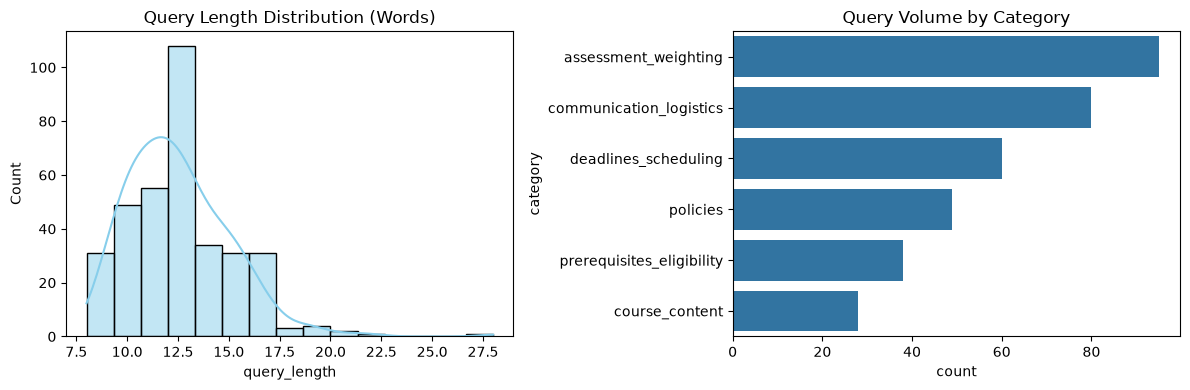

In [ ]:
# CELL 8: Step 3 & 4 - Local Evaluation Dataset (Reserved for Calibration & Test)
def chunk_text(text: str, chunk_size: int = 500, overlap: int = 50) -> List[str]:
    words = text.split()
    chunks = []
    step = max(chunk_size - overlap, 1)
    for i in range(0, len(words), step):
        chunk = " ".join(words[i:i + chunk_size]).strip()
        if chunk:
            chunks.append(chunk)
    return chunks


all_chunks = []
for doc_key, doc in documents_dict.items():
    for chunk in chunk_text(doc["text"]):
        all_chunks.append({
            "text": chunk,
            "course_code": doc["course_code"],
            "doc_type": doc["doc_type"],
            "source_document": doc_key,
        })
print(f"Total chunks created from local corpus: {len(all_chunks)}")


def load_faq_json_to_df(json_path: str) -> pd.DataFrame:
    with open(json_path, "r", encoding="utf-8") as f:
        raw_json = json.load(f)

    if isinstance(raw_json, list):
        return pd.DataFrame(raw_json)

    if isinstance(raw_json, dict):
        for key in ("faqs", "questions", "items", "data", "records", "dataset"):
            if isinstance(raw_json.get(key), list):
                return pd.DataFrame(raw_json[key])

        vals = list(raw_json.values())
        if vals and all(isinstance(v, dict) for v in vals):
            return pd.DataFrame.from_dict(raw_json, orient="index").reset_index(names="id")

        return pd.json_normalize(raw_json)

    raise ValueError(f"Unsupported JSON structure in {json_path}: {type(raw_json)}")


if os.path.exists("project2_faq_dataset.json"):
    faq_df = load_faq_json_to_df("project2_faq_dataset.json")
elif os.path.exists("project2_faq_dataset.csv"):
    faq_df = pd.read_csv("project2_faq_dataset.csv")
else:
    raise FileNotFoundError("Provide project2_faq_dataset.json or project2_faq_dataset.csv for evaluation.")

print("Loaded faq_df columns:", list(faq_df.columns), "| rows:", len(faq_df))

if "question_id" not in faq_df.columns:
    faq_df["question_id"] = [f"q_{idx}" for idx in range(len(faq_df))]
if "course_code" not in faq_df.columns:
    faq_df["course_code"] = "UNKNOWN"
if "answerable" not in faq_df.columns:
    faq_df["answerable"] = True
else:
    faq_df["answerable"] = faq_df["answerable"].astype(str).str.lower().isin(["true", "1", "yes"])

calib_df, test_df = train_test_split(
    faq_df,
    test_size=0.3,
    stratify=faq_df["answerable"] if faq_df["answerable"].nunique() > 1 else None,
    random_state=42,
)
print(f"Evaluation split -> Calibration: {len(calib_df)} | Held-out Test: {len(test_df)}")

faq_df["query_length"] = faq_df["question_text"].apply(lambda x: len(str(x).split()))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(faq_df["query_length"], bins=15, kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Query Length Distribution (Words)")
if "category" in faq_df.columns:
    sns.countplot(y="category", data=faq_df, order=faq_df["category"].value_counts().index, ax=axes[1])
    axes[1].set_title("Query Volume by Category")
plt.tight_layout()
plt.show()

## Phase 3 — Evaluation Split & Vector Store

### 3A. Prepare labeled FAQ questions for evaluation

The FAQ file is a separate evaluation set: its `answerable` column indicates whether the local knowledge base should contain enough information to answer a question. The notebook fills missing identifiers/context fields, then uses `train_test_split` to create:

- **Calibration set (70%):** used to inspect score distributions and compare candidate confidence thresholds.
- **Held-out test set (30%):** used once a threshold has been chosen, to estimate how the gate behaves on unseen examples.

Stratification preserves the answerable/unanswerable ratio where both labels are present. The fixed random seed makes the split repeatable. The plots are simple diagnostics of query length and category counts.

### 3B. Convert passages into searchable vectors

`all-MiniLM-L6-v2` encodes each text chunk as a dense embedding. ChromaDB persists those embeddings alongside the original chunk text and its metadata. At query time, the question is embedded in the same vector space and Chroma returns its nearest passages (`top-k`).

A known course code can restrict the search to that context. If the filtered query returns no documents, the code retries against the full collection. The vector database is only populated when it is empty, so changing the source documents does not automatically refresh an existing persistent index.

In [ ]:
# CELL 9: Phase 2 - Vector Store, DeBERTa-v3 (ONNX CPU) & Phi-4-mini (Ollama)
embedder = SentenceTransformer("all-MiniLM-L6-v2")
chroma_client = chromadb.PersistentClient(path="./vector_db_phase2")
collection = chroma_client.get_or_create_collection("university_knowledge_base")

if PHASE_2_LOCAL_DEPLOYMENT and all_chunks and collection.count() == 0:
    batch_size = 64
    for start in range(0, len(all_chunks), batch_size):
        batch = all_chunks[start:start + batch_size]
        embeddings = embedder.encode([c["text"] for c in batch]).tolist()
        collection.add(
            ids=[f"chunk_{start + j}" for j in range(len(batch))],
            embeddings=embeddings,
            documents=[c["text"] for c in batch],
            metadatas=[{
                "course_code": c["course_code"],
                "doc_type": c["doc_type"],
                "source_document": c["source_document"],
            } for c in batch],
        )
    print(f"Indexed {collection.count()} chunks into Phase 2 vector store.")
else:
    print(f"Vector store chunk count: {collection.count()}")


def _softmax(logits: np.ndarray) -> np.ndarray:
    shifted = logits - np.max(logits, axis=-1, keepdims=True)
    exp_vals = np.exp(shifted)
    return exp_vals / np.sum(exp_vals, axis=-1, keepdims=True)


ort_session = None
deberta_tokenizer = None

if USE_LOCAL_DEBERTA_ONNX and os.path.exists(DEBERTA_ONNX_MODEL_PATH):
    sess_options = ort.SessionOptions()
    sess_options.intra_op_num_threads = max(1, os.cpu_count() or 1)
    sess_options.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    ort_session = ort.InferenceSession(
        DEBERTA_ONNX_MODEL_PATH,
        sess_options=sess_options,
        providers=["CPUExecutionProvider"],
    )
    try:
        deberta_tokenizer = AutoTokenizer.from_pretrained(
            DEBERTA_TOKENIZER_DIR,
            fix_mistral_regex=True,
        )
    except TypeError:
        deberta_tokenizer = AutoTokenizer.from_pretrained(DEBERTA_TOKENIZER_DIR)

    print(f"Loaded DeBERTa-v3 ONNX model on CPU from {DEBERTA_ONNX_MODEL_PATH}")
elif USE_LOCAL_DEBERTA_ONNX:
    print(f"ONNX model not found at {DEBERTA_ONNX_MODEL_PATH}; falling back to metadata/keyword routing.")


def predict_deberta_onnx(query: str) -> Tuple[Optional[str], Optional[float]]:
    """Runs local DeBERTa-v3 classification on CPU via ONNX Runtime."""
    if ort_session is None or deberta_tokenizer is None:
        return None, None

    encoded = deberta_tokenizer(
        query,
        truncation=True,
        max_length=256,
        padding="max_length",
        return_tensors="np",
    )
    input_names = {inp.name for inp in ort_session.get_inputs()}
    ort_inputs = {}
    if "input_ids" in input_names:
        ort_inputs["input_ids"] = encoded["input_ids"].astype(np.int64)
    if "attention_mask" in input_names:
        ort_inputs["attention_mask"] = encoded["attention_mask"].astype(np.int64)
    if "token_type_ids" in input_names and "token_type_ids" in encoded:
        ort_inputs["token_type_ids"] = encoded["token_type_ids"].astype(np.int64)

    logits = ort_session.run(None, ort_inputs)[0][0]
    probs = _softmax(logits)
    pred_idx = int(np.argmax(probs))
    label = DEBERTA_LABELS[pred_idx] if pred_idx < len(DEBERTA_LABELS) else f"LABEL_{pred_idx}"
    return label, float(probs[pred_idx])

BROAD_OR_NON_UNIT_TARGETS = {
    "",
    "UNKNOWN",
    "NONE",
    "N/A",
    "UNIVERSITY_POLICY",
    "COURSE_SYLLABUS",
    "GENERAL_INQUIRY",
}


def _normalize_code(code: Optional[str]) -> Optional[str]:
    if not code or not isinstance(code, str):
        return None
    cleaned = re.sub(r"\s+", " ", code.strip().upper())
    m = re.match(r"^([A-Z]{2,4})\s?(\d{3,4})$", cleaned)
    return f"{m.group(1)} {m.group(2)}" if m else cleaned


def is_specific_unit_code(code: Optional[str]) -> bool:
    norm = _normalize_code(code)
    return bool(norm and norm not in BROAD_OR_NON_UNIT_TARGETS)


def _fallback_resolve_course_code(query: str) -> Optional[str]:
    """Fallback query-to-course resolver in case Cell 9 runs before Cell 2's helper is defined."""
    if "resolve_course_code_from_query" in globals() and callable(resolve_course_code_from_query):
        return _normalize_code(resolve_course_code_from_query(query))

    code_match = re.search(r"\b([A-Za-z]{2,4})\s?(\d{3,4})\b", query or "")
    if code_match:
        return f"{code_match.group(1).upper()} {code_match.group(2)}"

    q_low = (query or "").lower()
    fallback_names = {
        "integral calculus": "BBT 2104",
        "differential calculus": "ICS 1103",
        "calculus 1": "ICS 1103",
        "linear algebra": "ICS 1205",
        "software engineering": "ICS 2201",
        "web application development": "ICS 2102",
        "data structures and algorithms": "ICS 1201",
        "object oriented programming ii": "ICS 2101",
        "advanced database systems": "ICS 3101",
        "advanced networking": "ICS 2203",
        "digital logic": "ICS 2211",
        "assembly language programming": "ICS 3202",
        "computer graphics": "ICS 3204",
        "mobile application development": "ICS 3102",
        "business ethics": "HHE 3208",
        "east african societies": "HHE 3108",
        "world civilizations ii": "HHE 3210",
        "philosophical anthropology": "HED 1101",
        "probability and statistics i": "ICS 2206",
        "principles of management": "ICS 1206",
    }
    for name, code in sorted(fallback_names.items(), key=lambda item: len(item[0]), reverse=True):
        if re.search(rf"\b{re.escape(name)}\b", q_low):
            return code
    return None


def resolve_routing_details(
    query: str,
    explicit_course_code: Optional[str] = None,
) -> Tuple[Optional[str], Optional[float], bool]:
    """
    Returns (routed_code, route_conf, matched_specific_unit).
    matched_specific_unit is True only when a specific course unit code was selected or matched.
    """
    norm_explicit = _normalize_code(explicit_course_code)
    if is_specific_unit_code(norm_explicit):
        return norm_explicit, None, True

    inferred_code = _fallback_resolve_course_code(query)
    if is_specific_unit_code(inferred_code):
        return inferred_code, 1.0, True

    if norm_explicit == "UNIVERSITY_POLICY":
        return "UNIVERSITY_POLICY", None, False

    if USE_LOCAL_DEBERTA_ONNX and ort_session is not None:
        label, conf = predict_deberta_onnx(query)
        norm_label = _normalize_code(label)
        return norm_label, conf, is_specific_unit_code(norm_label)

    return None, None, False


def route_query(query: str, explicit_course_code: Optional[str] = None) -> Tuple[Optional[str], Optional[float]]:
    """Routes query using explicit course_code, query course name/code match, or local CPU ONNX DeBERTa-v3."""
    routed_code, route_conf, _ = resolve_routing_details(query, explicit_course_code=explicit_course_code)
    return routed_code, route_conf


def retrieve(
    query: str,
    course_code: Optional[str] = None,
    k: int = 3,
    allow_unfiltered_fallback: bool = False,
) -> Tuple[List[str], List[float], List[Dict[str, Any]]]:
    """Retrieves top-k chunks and metadata; does NOT pull unrelated courses when a specific unit is targeted."""
    query_embedding = embedder.encode(query).tolist()
    norm_code = _normalize_code(course_code)
    specific_unit = is_specific_unit_code(norm_code)
    where_filter = (
        {"course_code": norm_code}
        if (norm_code and norm_code not in {"UNKNOWN", "COURSE_SYLLABUS", "GENERAL_INQUIRY"})
        else None
    )

    results = collection.query(
        query_embeddings=[query_embedding],
        n_results=k,
        where=where_filter,
    )
    docs = results["documents"][0] if results.get("documents") else []
    distances = results["distances"][0] if results.get("distances") else []
    metadatas = results["metadatas"][0] if results.get("metadatas") else []

    if not docs and where_filter is not None and not specific_unit and allow_unfiltered_fallback:
        results = collection.query(query_embeddings=[query_embedding], n_results=k)
        docs = results["documents"][0] if results.get("documents") else []
        distances = results["distances"][0] if results.get("distances") else []
        metadatas = results["metadatas"][0] if results.get("metadatas") else []

    return docs, distances, metadatas


class AnswerResponse(BaseModel):
    answer: str
    confidence: float


def generate_with_phi4_mini(prompt: str) -> Tuple[str, float]:
    """Calls locally hosted Phi-4-mini via Ollama chat API."""
    payload = {
        "model": PHI4_MODEL,
        "messages": [
            {
                "role": "system",
                "content": "Respond ONLY with valid JSON matching keys 'answer' (str) and 'confidence' (float 0.0-1.0).",
            },
            {"role": "user", "content": prompt},
        ],
        "format": "json",
        "options": {"temperature": 0.2, "num_ctx": 2048, "num_predict": 180,},
        "keep_alive":"30m",
        "stream": False,
    }
    resp = requests.post(OLLAMA_URL, json=payload, timeout=40)
    resp.raise_for_status()
    content = resp.json()["message"]["content"]
    parsed = json.loads(content)
    return str(parsed.get("answer", "")), _parse_confidence(parsed.get("confidence", 0.0))


def generate_with_gemini(prompt: str) -> Tuple[str, float]:
    """Optional fallback to Gemini Flash Lite if ALLOW_GEMINI_FALLBACK is enabled."""
    api_key = os.environ.get("GEMINI_API_KEY", "").strip()
    if not api_key:
        return "", 0.0
    gemini_client = genai.Client(api_key=api_key)
    response = gemini_client.models.generate_content(
        model="gemini-3.1-flash-lite",
        contents=prompt,
        config=types.GenerateContentConfig(
            response_mime_type="application/json",
            response_schema=AnswerResponse,
            temperature=0.2,
        ),
    )
    result = json.loads(response.text)
    return result.get("answer", ""), float(result.get("confidence", 0.0))


def generate_answer(query: str, retrieved_chunks: List[str]) -> Tuple[str, float]:
    context = "\n\n".join(retrieved_chunks)
    prompt = f"""Answer the student's question using ONLY the context below.
If the context does not contain the answer, say so directly and set confidence low.

Context:
{context}

Question: {query}
"""
    if USE_LOCAL_PHI4_MINI:
        try:
            return generate_with_phi4_mini(prompt)
        except Exception as e:
            print(f"Local Phi-4-mini error ({e})")
            if not ALLOW_GEMINI_FALLBACK:
                return "", 0.0

    if ALLOW_GEMINI_FALLBACK:
        try:
            return generate_with_gemini(prompt)
        except Exception as e:
            print(f"Gemini fallback error: {e}")
    return "", 0.0

def _parse_confidence(raw_conf: Any) -> float:
    if isinstance(raw_conf, (int, float)):
        val = float(raw_conf)
    elif isinstance(raw_conf, str):
        s = raw_conf.strip().lower()
        word_map = {
            "very high": 0.9,
            "high": 0.85,
            "medium": 0.55,
            "moderate": 0.55,
            "low": 0.25,
            "very low": 0.1,
            "none": 0.0,
        }
        if s in word_map:
            return word_map[s]
        if s.endswith("%"):
            num = float(s[:-1].strip())
            val = num / 100.0 if num > 1.0 else num
        else:
            # Extract first float/int if wrapped in extra text
            match = re.search(r"[-+]?\d*\.?\d+", s)
            if not match:
                return 0.0
            val = float(match.group(0))
    else:
        return 0.0

    # Normalize percentage-like values (e.g., 85 -> 0.85) and clamp to [0.0, 1.0]
    if val > 1.0 and val <= 100.0:
        val = val / 100.0
    return min(max(val, 0.0), 1.0)

Vector store chunk count: 45
Loaded DeBERTa-v3 ONNX model on CPU from ./models/deberta-v3-onnx/model.onnx


### 3C. Query routing and answer generation

**Routing:** the query is tokenized and passed to a local DeBERTa-v3 model exported to ONNX. The model returns logits; softmax turns them into probabilities; `argmax` selects the highest-scoring route. The route labels must be in exactly the same order as the ONNX model's output classes. A manually selected course/context overrides automatic routing.

**Retrieval:** the user question is embedded and compared with indexed chunks. Chroma returns the nearest `k` passages, their distances, and source metadata.

**Generation:** retrieved passages are placed into a prompt that tells Phi-4-mini to answer only from that context and to say when the evidence is missing. The local Ollama model is tried first; Gemini can be used as a configured fallback. The model returns an answer and a self-reported confidence value, which is normalized to the range 0–1.

The model's confidence is only one signal. The next phase combines it with retrieval and grounding signals before deciding whether to show the answer.

## Phase 4 — Confidence Gating & Evaluation Results

### 4A. The binary decision rule

The notebook builds a heuristic score from three signals:

\[ S = 0.4(1-d) + 0.3G + 0.3C \]

where:
- `d` is the best (minimum) retrieval distance after clipping to the range 0–1;
- `G` is the lexical groundedness score (share of unique answer words also found in retrieved context);
- `C` is the generator's confidence, normalized to 0–1.

The rule is:

- `S ≥ threshold` → **auto-answer**;
- `S < threshold` → **escalate / withhold the draft**.

This is binary classification at the **decision layer**: the ground-truth label is `answerable`/`is_truly_answerable`, and the prediction is whether the system would auto-answer. The score itself is not a learned binary probability. In particular, lexical overlap is only a rough grounding proxy; shared words do not prove that the answer is entailed by the source.

### 4B. Calibration and held-out evaluation

The threshold sweep reports **coverage** (fraction of all questions the system would answer), **precision** (fraction of auto-answered questions labeled answerable), and the count of **wrongly answered** unanswerable questions. Increasing the threshold normally makes the system more cautious: coverage can fall while precision improves.

The notebook currently sets `best_threshold = 0.45` manually. The sweep prints alternatives but does not automatically optimize or assign that threshold. Evaluation CSVs are saved periodically and can resume by skipping question IDs already present in the file.

**Interpretation caution:** the formula treats the retrieval distance as if it were on a 0–1 scale. Chroma's distance meaning depends on the collection's distance metric and embedding configuration, so check the actual distance range before relying on `1 - distance` as a calibrated similarity. The reported score should be treated as a heuristic until validated for the deployed setup.

In [ ]:
# CELL 10: Step 7 & 8 - Confidence Gate, Calibration & Held-Out Test Evaluation
def groundedness_score(answer: str, retrieved_chunks: List[str]) -> float:
    if not answer or not retrieved_chunks:
        return 0.0
    answer_words = set(answer.lower().split())
    context_words = set(" ".join(retrieved_chunks).lower().split())
    return len(answer_words & context_words) / max(len(answer_words), 1)


def composite_confidence(
    retrieval_distance: float,
    groundedness: float,
    llm_confidence: float,
    w1: float = 0.4,
    w2: float = 0.3,
    w3: float = 0.3,
) -> float:
    retrieval_similarity = 1.0 - min(max(float(retrieval_distance), 0.0), 1.0)
    clamped_llm_conf = min(max(float(llm_confidence), 0.0), 1.0)
    return (w1 * retrieval_similarity) + (w2 * groundedness) + (w3 * clamped_llm_conf)


def _select_eval_rows(
    df: pd.DataFrame,
    max_rows: Optional[int] = None,
    stratified: bool = True,
    random_state: int = 42,
) -> pd.DataFrame:
    if max_rows is None or max_rows >= len(df):
        return df.copy()
    if stratified and "answerable" in df.columns and df["answerable"].nunique() > 1:
        sampled, _ = train_test_split(
            df,
            train_size=max_rows,
            stratify=df["answerable"],
            random_state=random_state,
        )
        return sampled
    return df.head(max_rows).copy()


def evaluate_dataset(
    df: pd.DataFrame,
    out_csv: str,
    sleep_sec: float = 0.0,
    max_rows: Optional[int] = None,
    stratified: bool = True,
    resume: bool = True,
    save_every: int = 5,
    k: int = 2,
) -> pd.DataFrame:
    work_df = _select_eval_rows(df, max_rows=max_rows, stratified=stratified)
    records: List[Dict[str, Any]] = []
    done_ids = set()

    out_path = Path(out_csv)
    if resume and out_path.exists():
        existing_df = pd.read_csv(out_path)
        if "question_id" in existing_df.columns:
            records = existing_df.to_dict("records")
            done_ids = set(existing_df["question_id"].astype(str))
            print(f"[{out_csv}] Resuming with {len(done_ids)} saved rows.")

    total = len(work_df)
    start_time = time.time()

    for idx, (_, row) in enumerate(work_df.iterrows(), start=1):
        qid = str(row["question_id"])
        if resume and qid in done_ids:
            continue

        row_start = time.time()
        routed_code, route_conf = route_query(row["question_text"], row.get("course_code"))
        chunks, distances, _ = retrieve(row["question_text"], routed_code, k=k)

        if not chunks:
            records.append({
                "question_id": row["question_id"],
                "routed_code": routed_code,
                "route_conf": route_conf,
                "composite_score": 0.0,
                "is_truly_answerable": bool(row["answerable"]),
                "generated_answer": "",
            })
        else:
            answer, llm_conf = generate_answer(row["question_text"], chunks)
            ground = groundedness_score(answer, chunks)
            min_dist = min(distances) if distances else 1.0
            score = composite_confidence(min_dist, ground, llm_conf)
            records.append({
                "question_id": row["question_id"],
                "routed_code": routed_code,
                "route_conf": route_conf,
                "composite_score": score,
                "is_truly_answerable": bool(row["answerable"]),
                "generated_answer": answer,
            })

        if idx % save_every == 0 or idx == total:
            pd.DataFrame(records).to_csv(out_csv, index=False)

        if idx == 1 or idx % 5 == 0 or idx == total:
            elapsed = time.time() - start_time
            row_dt = time.time() - row_start
            print(f"[{out_csv}] {idx}/{total} done | last={row_dt:.1f}s | elapsed={elapsed:.1f}s")

        if sleep_sec > 0:
            time.sleep(sleep_sec)

    res_df = pd.DataFrame(records)
    res_df.to_csv(out_csv, index=False)
    return res_df

def print_threshold_sweep(results_df: pd.DataFrame) -> None:
    print(f"{'threshold':>10} {'coverage':>10} {'precision':>10} {'wrongly_answered':>18}")
    for threshold in np.arange(0.3, 0.95, 0.05):
        would_auto = results_df["composite_score"] >= threshold
        coverage = would_auto.mean()
        correct = (would_auto & results_df["is_truly_answerable"]).sum()
        wrong = (would_auto & ~results_df["is_truly_answerable"]).sum()
        precision = correct / max(would_auto.sum(), 1)
        print(f"{threshold:>10.2f} {coverage:>10.2f} {precision:>10.2f} {wrong:>18}")


CALIB_MAX_ROWS = None
TEST_MAX_ROWS = None
best_threshold = 0.45

if "calib_df" not in globals() or "test_df" not in globals():
    print("calib_df or test_df is not defined yet. Fix and run # CELL 8 first.")
else:
    calib_results_df = evaluate_dataset(
        calib_df,
        "calibration_results_phase2.csv",
        max_rows=CALIB_MAX_ROWS,
        stratified=True,
        resume=True,
        k=2,
        sleep_sec=0.0,
    )
    print_threshold_sweep(calib_results_df)

    test_results_df = evaluate_dataset(
        test_df,
        "heldout_test_results_phase2.csv",
        max_rows=TEST_MAX_ROWS,
        stratified=True,
        resume=True,
        k=2,
        sleep_sec=0.0,
    )
    auto_mask = test_results_df["composite_score"] >= best_threshold
    print(
        f"\nHeld-out Test @ threshold={best_threshold:.2f} -> "
        f"Coverage: {auto_mask.mean():.2f}, "
        f"Precision: {(auto_mask & test_results_df['is_truly_answerable']).sum() / max(auto_mask.sum(), 1):.2f}"
    )

[calibration_results_phase2.csv] Resuming with 245 saved rows.
 threshold   coverage  precision   wrongly_answered
      0.30       0.81       0.97                  5
      0.35       0.75       0.98                  4
      0.40       0.74       0.98                  4
      0.45       0.73       0.98                  4
      0.50       0.65       0.97                  4
      0.55       0.56       0.99                  2
      0.60       0.41       0.98                  2
      0.65       0.02       1.00                  0
      0.70       0.00       0.00                  0
      0.75       0.00       0.00                  0
      0.80       0.00       0.00                  0
      0.85       0.00       0.00                  0
      0.90       0.00       0.00                  0
[heldout_test_results_phase2.csv] Resuming with 105 saved rows.

Held-out Test @ threshold=0.45 -> Coverage: 0.74, Precision: 0.97


## Phase 5 — Live Gradio Demo & Safeguards

The Gradio interface invokes the same routing → retrieval → generation → scoring path as offline evaluation. The dropdown supports automatic routing or an explicit course/policy context. When available, source document names and course codes are displayed so users can inspect which documents supported the response.

### Safeguards implemented in this notebook

1. **No retrieval results:** do not generate an answer; display an escalation message.
2. **Low composite confidence:** withhold the generated draft and show an escalation notice.
3. **Latency limit:** a worker thread enforces a 40-second response timeout and returns an escalation message when the limit is exceeded.
4. **Runtime failures:** catch exceptions and show a compact diagnostic instead of silently returning an answer.
5. **Context-constrained prompt:** instruct the generator to use only retrieved context and admit when the context is insufficient.

These safeguards improve caution and responsiveness, but they are not a complete production escalation system: the code displays an escalation message rather than actually creating an advisor ticket. It also does not implement authentication, rate limiting, or a semantic fact-checker. The citations identify source documents/metadata, not exact page or paragraph locations.

The next cell is an alternative CLI demo enclosed in a triple-quoted string, so it is inactive as written. The final cell is a small five-row evaluation/debug run.

In [ ]:
# Gradio-based Live Demo for University Student Query Routing & RAG Assistant
from concurrent.futures import ThreadPoolExecutor, TimeoutError as FuturesTimeoutError
import os
from pathlib import Path
import re
import time
import traceback

os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"

import gradio as gr

CONFIDENCE_THRESHOLD = 0.45
RESPONSE_TIMEOUT_SEC = 40.0
AUTO_DETECT_OPTION = "Auto-Detect (DeBERTa-v3 ONNX)"
SCHOOL_CHOICES = ["SCES", "SIMS", "SLS", "SBS", "SHSS", "SIMT", "STH"]
DEFAULT_SCHOOL = SCHOOL_CHOICES[0]
_DEMO_EXECUTOR = ThreadPoolExecutor(max_workers=2)

UNIVERSITY_KEYWORDS = {
    "university", "campus", "college", "faculty", "department", "school",
    "course", "courses", "unit", "units", "module", "modules", "syllabus",
    "outline", "lecture", "lectures", "lecturer", "professor", "instructor",
    "ta", "tutor", "cat", "cats", "exam", "exams", "examination", "quiz",
    "quizzes", "assignment", "assignments", "coursework", "lab", "labs",
    "practical", "project", "grade", "grades", "grading", "score", "gpa",
    "credit", "credits", "semester", "trimester", "timetable", "schedule",
    "attendance", "policy", "policies", "regulation", "regulations",
    "rule", "rules", "handbook", "guideline", "guidelines", "plagiarism",
    "cheating", "defer", "deferment", "retake", "supplementary", "registration",
    "enroll", "enrol", "enrollment", "add/drop", "fee", "fees", "tuition",
    "invoice", "scholarship", "bursary", "graduation", "gown", "transcript",
    "certificate", "library", "portal", "lms", "student", "students",
    "advisor", "adviser", "registrar", "dean",
}


def _collect_course_codes(course_folder: str = "./course_documents") -> List[str]:
    """Collects unique valid course codes from documents_dict, course_documents folder, and ChromaDB."""
    codes = set()

    if "documents_dict" in globals() and isinstance(documents_dict, dict):
        for doc in documents_dict.values():
            code = re.sub(r"\s+", " ", str((doc or {}).get("course_code") or "").strip().upper())
            if code and code not in {"UNKNOWN", "UNIVERSITY_POLICY", "NONE", "N/A"}:
                codes.add(code)

    folder_path = Path(course_folder)
    if folder_path.exists() and folder_path.is_dir():
        for file_path in sorted(folder_path.iterdir()):
            if not file_path.is_file() or file_path.name.startswith("~$"):
                continue
            code, _ = detect_course_code_and_type("", file_path.name)
            code = re.sub(r"\s+", " ", str(code).strip().upper())
            if code in {"UNKNOWN", "UNIVERSITY_POLICY"}:
                fn_match = re.search(r"\b([A-Za-z]{2,4}\s?\d{3,4})\b", file_path.stem)
                if fn_match:
                    code = re.sub(r"\s+", " ", fn_match.group(1).upper()).strip()
            if code and code not in {"UNKNOWN", "UNIVERSITY_POLICY", "NONE", "N/A"}:
                codes.add(code)

    if "collection" in globals() and collection is not None:
        try:
            existing = collection.get(include=["metadatas"])
            for meta in existing.get("metadatas") or []:
                code = re.sub(r"\s+", " ", str((meta or {}).get("course_code") or "").strip().upper())
                if code and code not in {"UNKNOWN", "UNIVERSITY_POLICY", "NONE", "N/A"}:
                    codes.add(code)
        except Exception:
            pass

    return sorted(codes)


def _get_dropdown_choices() -> List[str]:
    choices = [AUTO_DETECT_OPTION, "UNIVERSITY_POLICY"]
    for code in _collect_course_codes("./course_documents"):
        if code not in choices:
            choices.append(code)
    return choices


def _normalize_school(selected_school: Optional[str]) -> str:
    val = str(selected_school or "").strip().upper()
    return val if val in SCHOOL_CHOICES else DEFAULT_SCHOOL


def _format_escalation_header(
    routed_code: Optional[str],
    matched_specific_unit: bool,
    selected_school: str,
) -> str:
    school = _normalize_school(selected_school)
    cleaned_code = re.sub(r"\s+", " ", str(routed_code or "").strip().upper())
    non_unit = {"", "UNKNOWN", "NONE", "N/A", "UNIVERSITY_POLICY", "COURSE_SYLLABUS", "GENERAL_INQUIRY"}

    if matched_specific_unit and cleaned_code and cleaned_code not in non_unit:
        return f"**[ESCALATED TO {cleaned_code} LECTURER QUEUE]**"
    return f"**[ESCALATED TO {school} ADMINISTRATOR/ADVISOR QUEUE]**"


def _looks_like_gibberish(text: str) -> bool:
    """Flags whitespace-only or random non-word strings as invalid input."""
    tokens = re.findall(r"[A-Za-z]+", text)
    if not tokens:
        return True

    meaningful_words = []
    for tok in tokens:
        low = tok.lower()
        if len(low) >= 4:
            if not re.search(r"[aeiouy]", low):
                return True
            if re.search(r"[bcdfghjklmnpqrstvwxz]{5,}", low):
                return True
            meaningful_words.append(low)
        elif len(low) >= 2:
            meaningful_words.append(low)

    if len(tokens) == 1 and len(tokens[0]) > 10 and not re.search(r"[aeiouy]{2}", tokens[0].lower()):
        return True

    return len(meaningful_words) == 0


def _is_university_related(
    query: str,
    selected_course: str,
    routed_code: Optional[str] = None,
    min_distance: Optional[float] = None,
) -> bool:
    """Determines whether a query relates to university academics, courses, policies, or campus life."""
    if selected_course != AUTO_DETECT_OPTION:
        return True

    if routed_code and routed_code not in {"UNKNOWN", "COURSE_SYLLABUS", "GENERAL_INQUIRY"}:
        return True

    q_lower = query.lower()
    if re.search(r"\b[a-z]{2,4}\s?\d{3,4}\b", q_lower):
        return True

    words = set(re.findall(r"[a-z0-9/+-]+", q_lower))
    if words & UNIVERSITY_KEYWORDS:
        return True
    if any(phrase in q_lower for phrase in ("course outline", "class attendance", "graduation gown", "fee structure")):
        return True

    if min_distance is not None and min_distance <= 0.65:
        return True

    return False


def _validate_query(message: Any) -> Optional[str]:
    """Returns an error message if input is invalid or irrelevant; returns None if valid."""
    if message is None or not isinstance(message, str):
        return (
            "**[INVALID INPUT — IGNORED]**\n"
            "Please enter a valid text question related to university courses, syllabi, or policies."
        )

    cleaned = message.strip()
    if not cleaned:
        return (
            "**[INVALID INPUT — IGNORED]**\n"
            "Empty or whitespace-only input is not allowed. Please enter a university-related question."
        )

    if _looks_like_gibberish(cleaned):
        return (
            "**[INVALID INPUT — IGNORED]**\n"
            f"Your input (`{cleaned[:60]}`) appears to be invalid or gibberish. "
            "Please enter a clear question related to the university."
        )

    return None


def _format_citations(metadatas: List[Dict[str, Any]], distances: List[float]) -> str:
    if not metadatas:
        return "- *No source metadata available*"

    seen = set()
    lines = []
    for idx, meta in enumerate(metadatas):
        meta = meta or {}
        src = meta.get("source_document") or "Unknown document"
        code = meta.get("course_code") or "N/A"
        dist = distances[idx] if idx < len(distances) else None
        key = (src, code)
        if key in seen:
            continue
        seen.add(key)
        if dist is not None:
            lines.append(f"- `{src}` *(Course: `{code}`, dist: `{dist:.3f}`)*")
        else:
            lines.append(f"- `{src}` *(Course: `{code}`)*")
    return "\n".join(lines)


def _run_rag_pipeline(message: str, selected_course: str, selected_school: str) -> str:
    validation_error = _validate_query(message)
    if validation_error:
        return validation_error

    school = _normalize_school(selected_school)
    course_arg = None if selected_course == AUTO_DETECT_OPTION else selected_course

    if "resolve_routing_details" in globals() and callable(resolve_routing_details):
        routed_code, route_conf, matched_specific_unit = resolve_routing_details(
            message, explicit_course_code=course_arg
        )
    else:
        routed_code, route_conf = route_query(message, explicit_course_code=course_arg)
        norm_rc = re.sub(r"\s+", " ", str(routed_code or "").strip().upper())
        matched_specific_unit = bool(
            norm_rc and norm_rc not in {"UNKNOWN", "NONE", "N/A", "UNIVERSITY_POLICY", "COURSE_SYLLABUS", "GENERAL_INQUIRY"}
        )

    chunks, distances, metadatas = retrieve(message, routed_code, k=2, allow_unfiltered_fallback=False)
    min_dist = min(distances) if distances else 1.0

    if not _is_university_related(message, selected_course, routed_code=routed_code, min_distance=min_dist):
        return (
            "**[IRRELEVANT QUERY — IGNORED]**\n"
            "This assistant only handles questions and requests related to the university "
            "(courses, outlines, policies, and academic support). Off-topic queries are ignored "
            "and not forwarded to any queue."
        )

    escalation_header = _format_escalation_header(routed_code, matched_specific_unit, school)

    if not chunks:
        target_label = routed_code if matched_specific_unit else school
        return (
            f"{escalation_header}\n"
            f"- **Routed Target:** `{target_label}`\n"
            f"- **Reason:** University-related query, but no matching knowledge base documents were found."
        )

    answer, llm_conf = generate_answer(message, chunks)
    ground = groundedness_score(answer, chunks)
    comp_score = composite_confidence(min_dist, ground, llm_conf)
    route_str = f"{routed_code} ({route_conf:.2f})" if route_conf is not None else f"{routed_code} (Selected)"

    if comp_score >= CONFIDENCE_THRESHOLD:
        citations_block = f"**Supporting Documents:**\n{_format_citations(metadatas, distances)}"
        return (
            f"{answer}\n\n"
            f"---\n"
            f"{citations_block}\n\n"
            f"**Routing:** `{route_str}` | "
            f"**Composite Confidence:** `{comp_score:.2f}` (Threshold: `{CONFIDENCE_THRESHOLD:.2f}`)\n"
            f"**Decision:** `AUTO-ANSWERED`"
        )

    # Escalated response: omits Supporting Documents and routes to unit lecturer or school admin/advisor
    return (
        f"{escalation_header}\n"
        f"University-related query had confidence (`{comp_score:.2f}`) below threshold (`{CONFIDENCE_THRESHOLD:.2f}`). "
        f"Escalated for review.\n\n"
        f"---\n"
        f"**Routing:** `{route_str}` | **School:** `{school}` | "
        f"**Composite Confidence:** `{comp_score:.2f}` (Threshold: `{CONFIDENCE_THRESHOLD:.2f}`)"
    )


def live_demo_chat(message, history, selected_course, selected_school):
    school = _normalize_school(selected_school)
    course_arg = None if selected_course == AUTO_DETECT_OPTION else selected_course
    matched_specific_unit = False
    routed_code = None

    if isinstance(message, str) and message.strip():
        try:
            if "resolve_routing_details" in globals() and callable(resolve_routing_details):
                routed_code, _, matched_specific_unit = resolve_routing_details(
                    message.strip(), explicit_course_code=course_arg
                )
        except Exception:
            pass

    start_ts = time.time()
    future = _DEMO_EXECUTOR.submit(_run_rag_pipeline, message, selected_course, school)
    try:
        return future.result(timeout=RESPONSE_TIMEOUT_SEC)
    except FuturesTimeoutError:
        future.cancel()
        elapsed = time.time() - start_ts
        header = _format_escalation_header(routed_code, matched_specific_unit, school)
        return (
            f"{header}\n"
            f"Response exceeded the `{RESPONSE_TIMEOUT_SEC:.0f}s` latency limit "
            f"(elapsed: `{elapsed:.1f}s`). Escalated to keep the assistant responsive."
        )
    except Exception as exc:
        tb_last = traceback.format_exc().splitlines()[-3:]
        return f"**Demo Runtime Error:** `{type(exc).__name__}: {exc}`\n\n```text\n" + "\n".join(tb_last) + "\n```"


dropdown_choices = _get_dropdown_choices()

demo = gr.ChatInterface(
    fn=live_demo_chat,
    title="University Student Query Routing & RAG Assistant (Live Demo)",
    description="Powered by DeBERTa-v3 (CPU ONNX Runtime) + ChromaDB + Phi-4-mini (Ollama)",
    additional_inputs=[
        gr.Dropdown(
            choices=dropdown_choices,
            value=AUTO_DETECT_OPTION,
            label="Course / Context Filter",
        ),
        gr.Dropdown(
            choices=SCHOOL_CHOICES,
            value=DEFAULT_SCHOOL,
            label="Enrolled School",
        ),
    ],
    examples=[
        ["What is the score distribution across final exam, CATs, and coursework for ICS 3203?", "ICS 3203", "SCES"],
        ["Who is the lecturer for the Integral Calculus Unit?", AUTO_DETECT_OPTION, "SCES"],
        ["What is the university policy on class attendance?", AUTO_DETECT_OPTION, "SIMS"],
    ],
)
demo.launch(inbrowser=True)

## Final interpretation and practical checks

### What the complete system does

1. Ingest local documents and extract text.
2. Split documents into overlapping retrieval passages.
3. Embed and persist passages with course/source metadata.
4. Classify the query's topic with DeBERTa (three routing classes).
5. Retrieve the nearest passages and generate a context-based draft.
6. Combine retrieval distance, lexical groundedness, and LLM confidence.
7. Make a binary threshold decision: answer automatically or withhold/escalate.

### Important implementation notes

- The notebook contains exploratory public-data cells before the consolidated Phase 1 loader. The later cell redefines `load_kaggle_university_intents`; run cells in order to use the consolidated implementation.
- The JSON repair cell has a machine-specific absolute path and overwrites its target file.
- The ONNX output class order must match `DEBERTA_LABELS` exactly.
- The fallback message in the router setup mentions metadata/keyword routing, but `route_query` currently returns `(None, None)` if DeBERTa is unavailable and no explicit course was selected.
- The persistent Chroma collection is only indexed when its count is zero. Rebuild or version the collection when the document corpus changes.
- `best_threshold` and the Gradio `CONFIDENCE_THRESHOLD` are set separately; keep them aligned after evaluation.
- A timeout response protects the interface, but thread-pool timeout does not necessarily terminate the underlying model request.
- The evaluation reports coverage, precision, and wrongly answered counts; it does not currently report recall, F1, calibration error, or confidence intervals.

### Suggested run order

Run from top to bottom after installing dependencies, preparing the three local document folders and FAQ evaluation file, setting credentials, and confirming that the ONNX model plus Ollama service are available. Review the calibration sweep, validate the chosen threshold on the held-out set, then launch the Gradio demo.